In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
%matplotlib inline
sns.set(color_codes=True)
import warnings
warnings.filterwarnings("ignore")

In [4]:
df = pd.read_csv(r"C:\Users\Admin\Desktop\UM ASSIGNMENTS\greendestination (1).csv")
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [5]:
df.shape

(1470, 35)

In [6]:
df.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [8]:
df.isnull().sum().sum()

np.int64(0)

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
[c for c in df.columns if df[c].nunique() == 1]

['EmployeeCount', 'Over18', 'StandardHours']

In [11]:
attrition_counts = df['Attrition'].value_counts()
attrition_rate = (df['Attrition'] == 'Yes').mean()

print(f"Attrition Rate: {attrition_rate:.2%}")
print(f"Employees who left: {attrition_counts['Yes']}")
print(f"Employees who stayed: {attrition_counts['No']}")
print(f"Total employees: {len(df)}")

Attrition Rate: 16.12%
Employees who left: 237
Employees who stayed: 1233
Total employees: 1470


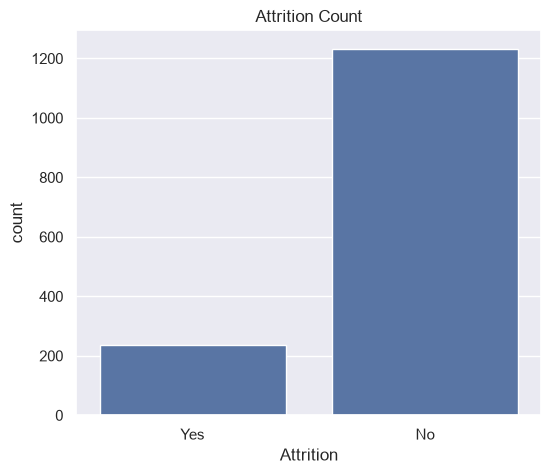

In [12]:
plt.figure(figsize=(6,5))
sns.countplot(x='Attrition', data=df)
plt.title('Attrition Count')
plt.show()

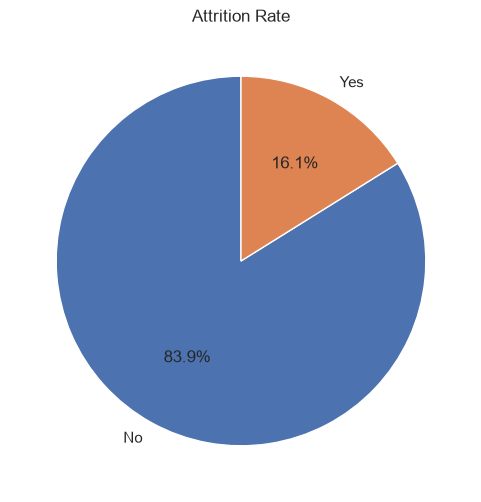

In [13]:
plt.figure(figsize=(6,6))
attrition_counts.plot(kind='pie', autopct='%1.1f%%', colors=['#4C72B0','#DD8452'], startangle=90)
plt.title('Attrition Rate')
plt.ylabel('')
plt.show()

In [14]:
age_stats = df.groupby('Attrition')['Age'].agg(['mean','median','std'])
age_stats

,mean,median,std
Attrition,,,
No,37.561233,36.0,8.88836
Yes,33.607595,32.0,9.68935


In [15]:
age_yes = df[df['Attrition']=='Yes']['Age']
age_no = df[df['Attrition']=='No']['Age']
t_age, p_age = stats.ttest_ind(age_yes, age_no, equal_var=False)

print(f"t-statistic = {t_age:.4f}")
print(f"p-value = {p_age:.6f}")
print(f"Significant at alpha=0.05: {p_age < 0.05}")

t-statistic = -5.8280
p-value = 0.000000
Significant at alpha=0.05: True


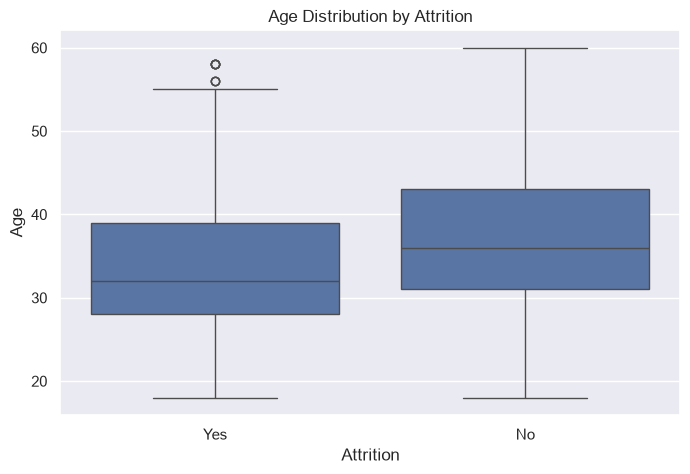

In [16]:
plt.figure(figsize=(8,5))
sns.boxplot(x='Attrition', y='Age', data=df)
plt.title('Age Distribution by Attrition')
plt.show()

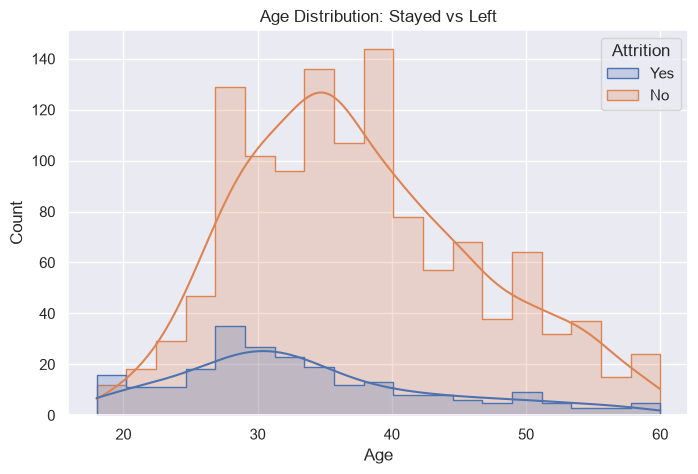

In [17]:
plt.figure(figsize=(8,5))
sns.histplot(data=df, x='Age', hue='Attrition', kde=True, element='step')
plt.title('Age Distribution: Stayed vs Left')
plt.show()
     

In [18]:
tenure_stats = df.groupby('Attrition')['YearsAtCompany'].agg(['mean','median','std'])
tenure_stats

,mean,median,std
Attrition,,,
No,7.369019,6.0,6.096298
Yes,5.130802,3.0,5.949984


In [19]:
tenure_yes = df[df['Attrition']=='Yes']['YearsAtCompany']
tenure_no = df[df['Attrition']=='No']['YearsAtCompany']
t_ten, p_ten = stats.ttest_ind(tenure_yes, tenure_no, equal_var=False)

print(f"t-statistic = {t_ten:.4f}")
print(f"p-value = {p_ten:.6f}")
print(f"Significant at alpha=0.05: {p_ten < 0.05}")

t-statistic = -5.2826
p-value = 0.000000
Significant at alpha=0.05: True


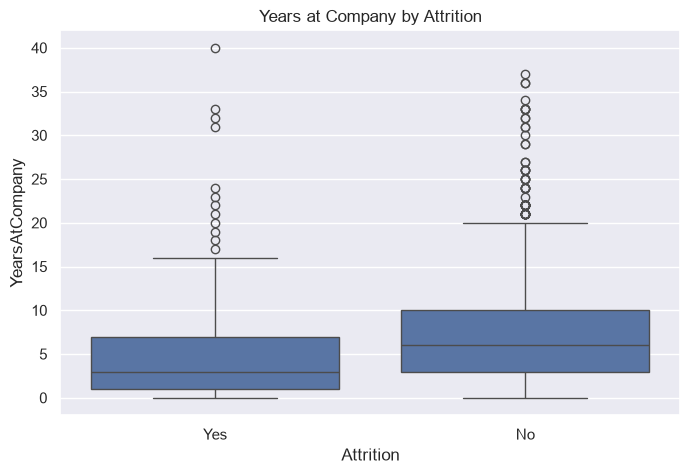

In [20]:
plt.figure(figsize=(8,5))
sns.boxplot(x='Attrition', y='YearsAtCompany', data=df)
plt.title('Years at Company by Attrition')
plt.show()

In [21]:
df['Tenure_Bucket'] = pd.cut(df['YearsAtCompany'], bins=[-1,1,3,5,10,50], labels=['0-1','2-3','4-5','6-10','10+'])
tenure_bucket_rate = df.groupby('Tenure_Bucket')['Attrition'].apply(lambda x: (x=='Yes').mean())
tenure_bucket_rate

Tenure_Bucket
0-1     0.348837
2-3     0.184314
4-5     0.130719
6-10    0.122768
10+     0.081301
Name: Attrition, dtype: float64

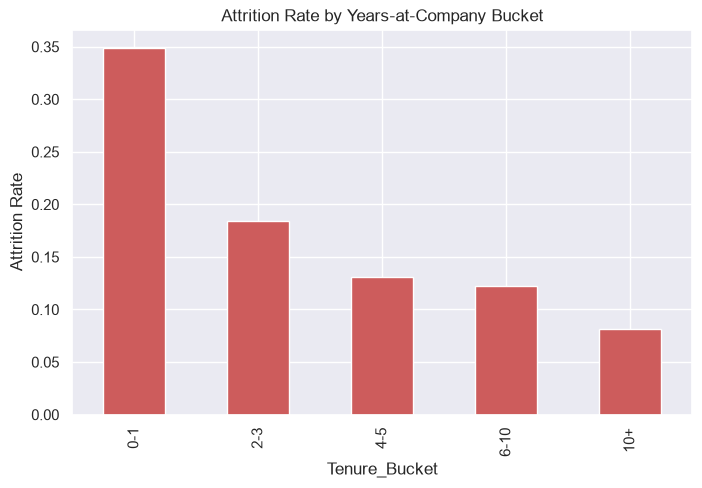

In [22]:
plt.figure(figsize=(8,5))
tenure_bucket_rate.plot(kind='bar', color='indianred')
plt.title('Attrition Rate by Years-at-Company Bucket')
plt.ylabel('Attrition Rate')
plt.show()

In [23]:
income_stats = df.groupby('Attrition')['MonthlyIncome'].agg(['mean','median','std'])
income_stats

,mean,median,std
Attrition,,,
No,6832.739659,5204.0,4818.208001
Yes,4787.092827,3202.0,3640.210367


In [24]:
income_yes = df[df['Attrition']=='Yes']['MonthlyIncome']
income_no = df[df['Attrition']=='No']['MonthlyIncome']
t_inc, p_inc = stats.ttest_ind(income_yes, income_no, equal_var=False)

print(f"t-statistic = {t_inc:.4f}")
print(f"p-value = {p_inc:.6f}")
print(f"Significant at alpha=0.05: {p_inc < 0.05}")
     

t-statistic = -7.4826
p-value = 0.000000
Significant at alpha=0.05: True


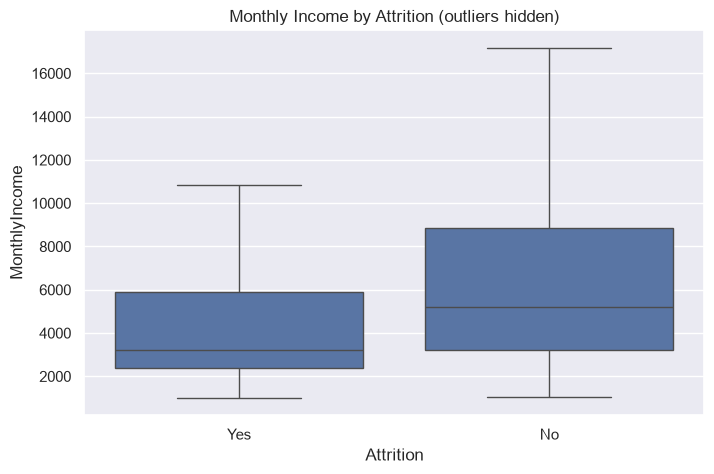

In [25]:
plt.figure(figsize=(8,5))
sns.boxplot(x='Attrition', y='MonthlyIncome', data=df, showfliers=False)
plt.title('Monthly Income by Attrition (outliers hidden)')
plt.show()

In [26]:
df['Income_Quartile'] = pd.qcut(df['MonthlyIncome'], 4, labels=['Q1 (lowest)','Q2','Q3','Q4 (highest)'])
income_q_rate = df.groupby('Income_Quartile')['Attrition'].apply(lambda x: (x=='Yes').mean())
income_q_rate

Income_Quartile
Q1 (lowest)     0.292683
Q2              0.142077
Q3              0.106267
Q4 (highest)    0.103261
Name: Attrition, dtype: float64

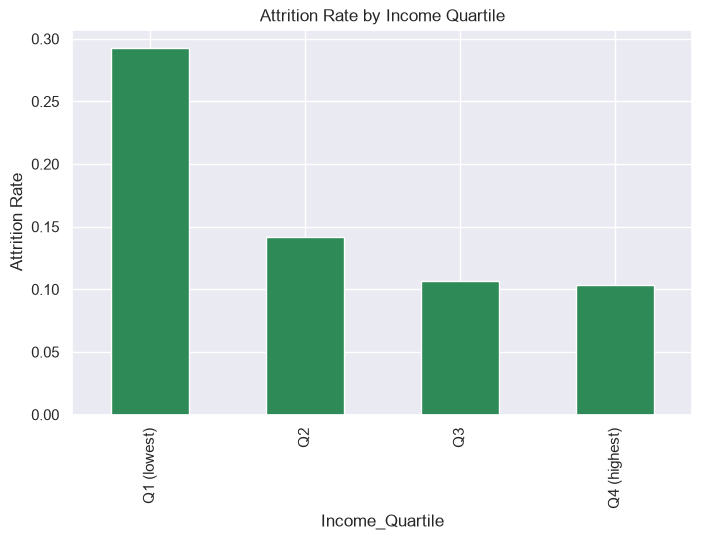

In [27]:
plt.figure(figsize=(8,5))
income_q_rate.plot(kind='bar', color='seagreen')
plt.title('Attrition Rate by Income Quartile')
plt.ylabel('Attrition Rate')
plt.show()

In [28]:
df['Attrition_num'] = (df['Attrition']=='Yes').astype(int)
corr_cols = ['Age','YearsAtCompany','MonthlyIncome','Attrition_num']
corr = df[corr_cols].corr()
corr

,Age,YearsAtCompany,MonthlyIncome,Attrition_num
Age,1.000000,0.311309,0.497855,-0.159205
YearsAtCompany,0.311309,1.000000,0.514285,-0.134392
MonthlyIncome,0.497855,0.514285,1.000000,-0.159840
Attrition_num,-0.159205,-0.134392,-0.159840,1.000000


In [29]:
df['Attrition_num'] = (df['Attrition']=='Yes').astype(int)
corr_cols = ['Age','YearsAtCompany','MonthlyIncome','Attrition_num']
corr = df[corr_cols].corr()
corr

,Age,YearsAtCompany,MonthlyIncome,Attrition_num
Age,1.000000,0.311309,0.497855,-0.159205
YearsAtCompany,0.311309,1.000000,0.514285,-0.134392
MonthlyIncome,0.497855,0.514285,1.000000,-0.159840
Attrition_num,-0.159205,-0.134392,-0.159840,1.000000


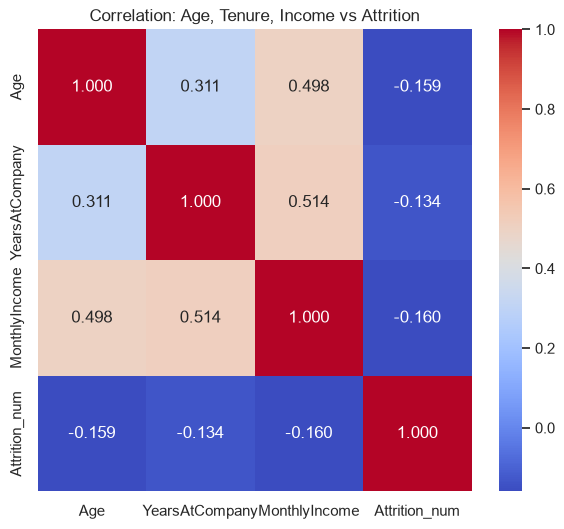

In [30]:
plt.figure(figsize=(7,6))
sns.heatmap(corr, annot=True, fmt='.3f', cmap='coolwarm')
plt.title('Correlation: Age, Tenure, Income vs Attrition')
plt.show()

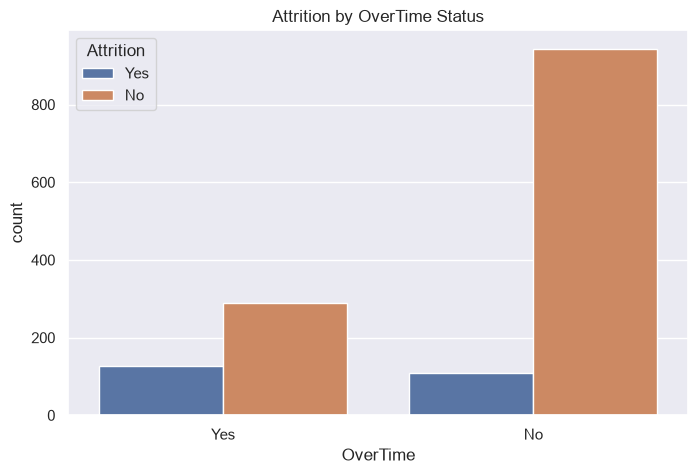

In [31]:
plt.figure(figsize=(8,5))
sns.countplot(x='OverTime', hue='Attrition', data=df)
plt.title('Attrition by OverTime Status')
plt.show()

In [32]:
overtime_rate = df.groupby('OverTime')['Attrition'].apply(lambda x: (x=='Yes').mean())
overtime_rate

OverTime
No     0.104364
Yes    0.305288
Name: Attrition, dtype: float64

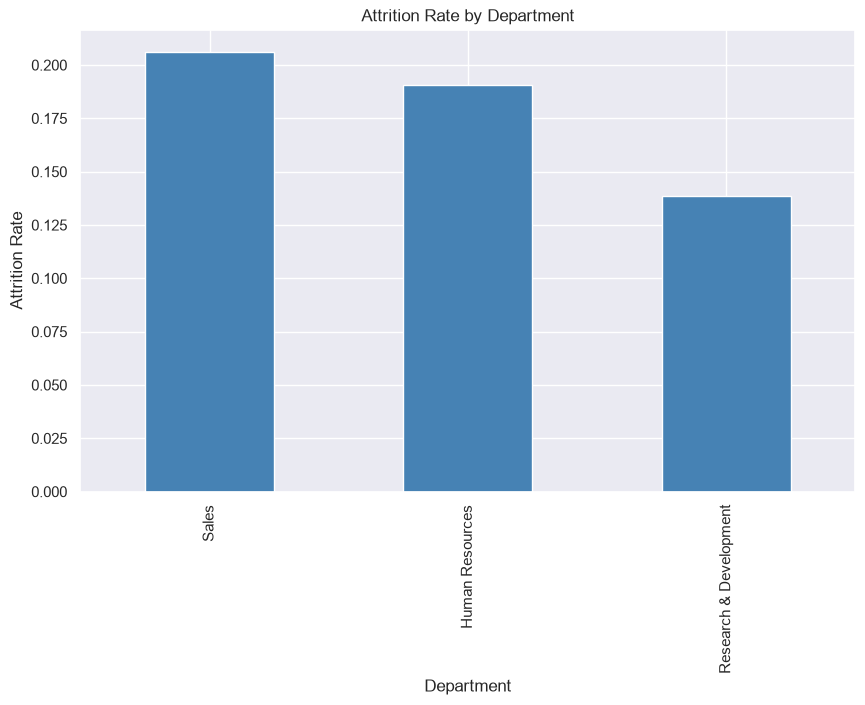

In [33]:
plt.figure(figsize=(10,6))
dept_rate = df.groupby('Department')['Attrition'].apply(lambda x: (x=='Yes').mean()).sort_values(ascending=False)
dept_rate.plot(kind='bar', color='steelblue')
plt.title('Attrition Rate by Department')
plt.ylabel('Attrition Rate')
plt.show()